In [6]:
# BINGEPLAY DATA ANALYSIS PROJECT

print("BINGEPLAY DATA ANALYSIS")
print("Project initialization successful!")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("\nAll libraries imported successfully!")

BINGEPLAY DATA ANALYSIS
Project initialization successful!

All libraries imported successfully!


In [7]:
from google.colab import files

uploaded = files.upload()

print("\nFiles uploaded successfully:")
for filename in uploaded.keys():
    print(filename)

Saving bingeplay_ratings.sql to bingeplay_ratings (2).sql
Saving bingeplay_shows.sql to bingeplay_shows (2).sql
Saving bingeplay_subscriptions.sql to bingeplay_subscriptions (2).sql
Saving bingeplay_users.sql to bingeplay_users (2).sql
Saving bingeplay_watch_sessions.sql to bingeplay_watch_sessions (2).sql

Files uploaded successfully:
bingeplay_ratings (2).sql
bingeplay_shows (2).sql
bingeplay_subscriptions (2).sql
bingeplay_users (2).sql
bingeplay_watch_sessions (2).sql


In [8]:
import sqlite3
import pandas as pd
import os

# Create database connection
conn = sqlite3.connect("bingeplay.db")

print("Database connection created successfully!")

Database connection created successfully!


In [9]:
for filename in uploaded.keys():
    print("\nFILE:", filename)
    with open(filename, "r", encoding="utf-8", errors="ignore") as f:
        print(f.read(500))


FILE: bingeplay_ratings (2).sql
-- MySQL dump 10.13  Distrib 8.0.46, for Win64 (x86_64)
--
-- Host: 127.0.0.1    Database: bingeplay
-- ------------------------------------------------------
-- Server version	8.0.46

/*!40101 SET @OLD_CHARACTER_SET_CLIENT=@@CHARACTER_SET_CLIENT */;
/*!40101 SET @OLD_CHARACTER_SET_RESULTS=@@CHARACTER_SET_RESULTS */;
/*!40101 SET @OLD_COLLATION_CONNECTION=@@COLLATION_CONNECTION */;
/*!50503 SET NAMES utf8 */;
/*!40103 SET @OLD_TIME_ZONE=@@TIME_ZONE */;
/*!40103 SET TIME_ZONE='+00:00' */;
/*!4001

FILE: bingeplay_shows (2).sql
-- MySQL dump 10.13  Distrib 8.0.46, for Win64 (x86_64)
--
-- Host: 127.0.0.1    Database: bingeplay
-- ------------------------------------------------------
-- Server version	8.0.46

/*!40101 SET @OLD_CHARACTER_SET_CLIENT=@@CHARACTER_SET_CLIENT */;
/*!40101 SET @OLD_CHARACTER_SET_RESULTS=@@CHARACTER_SET_RESULTS */;
/*!40101 SET @OLD_COLLATION_CONNECTION=@@COLLATION_CONNECTION */;
/*!50503 SET NAMES utf8 */;
/*!40103 SET @OLD_TIME

In [10]:
import os

for filename in uploaded.keys():
    print("\n" + "="*60)
    print("FILE:", filename)
    print("="*60)

    with open(filename, "r", encoding="utf-8", errors="ignore") as f:
        content = f.readlines()

    for line in content:
        if "CREATE TABLE" in line.upper() or "INSERT INTO" in line.upper():
            print(line[:500])


FILE: bingeplay_ratings (2).sql
CREATE TABLE `ratings` (

INSERT INTO `ratings` VALUES (1,'U02539','S008',5,'2024-01-21'),(2,'U00950','S061',4,'2024-03-12'),(3,'U00744','S098',3,'2024-04-17'),(4,'U00336','S077',2,'2024-01-01'),(5,'U01089','S092',5,'2024-03-28'),(6,'U02280','S086',3,'2024-03-03'),(7,'U01137','S016',4,'2024-01-25'),(8,'U00457','S013',4,'2024-01-03'),(9,'U02860','S045',5,'2024-05-09'),(10,'U01653','S074',4,'2024-02-02'),(11,'U00533','S041',3,'2024-05-28'),(12,'U00424','S068',3,'2024-01-18'),(13,'U01833','S034',5,'2024-01-23'),(14,'U00057'

FILE: bingeplay_shows (2).sql
CREATE TABLE `shows` (

INSERT INTO `shows` VALUES ('S001','Kahani Ghar Ghar Ki','Action','English',2021,6.9,0,'Basic'),('S002','Show Special 4','Romance','Tamil',2020,6.9,0,'Basic'),('S003','Karnataka Kings','Drama','Hindi',2023,6.7,0,'Basic'),('S004','Show Special 20','Drama','Tamil',2022,6.0,0,'Family'),('S005','Show Special 27','Thriller','Bengali',2023,7.9,1,'Premium'),('S006','Show Special 8','Drama'

In [11]:
import re

for filename in uploaded.keys():

    print("\n" + "="*60)
    print("FILE:", filename)
    print("="*60)

    with open(filename, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    tables = re.findall(
        r'CREATE TABLE.*?;',
        content,
        flags=re.IGNORECASE | re.DOTALL
    )

    for table in tables:
        print(table)
        print("\n")


FILE: bingeplay_ratings (2).sql
CREATE TABLE `ratings` (
  `rating_id` int NOT NULL,
  `user_id` varchar(10) NOT NULL,
  `show_id` varchar(10) NOT NULL,
  `stars` tinyint NOT NULL,
  `rated_date` date NOT NULL,
  PRIMARY KEY (`rating_id`),
  KEY `idx_user` (`user_id`),
  KEY `idx_show` (`show_id`),
  KEY `idx_stars` (`stars`),
  CONSTRAINT `ratings_ibfk_1` FOREIGN KEY (`user_id`) REFERENCES `users` (`user_id`),
  CONSTRAINT `ratings_ibfk_2` FOREIGN KEY (`show_id`) REFERENCES `shows` (`show_id`)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4 COLLATE=utf8mb4_0900_ai_ci;



FILE: bingeplay_shows (2).sql
CREATE TABLE `shows` (
  `show_id` varchar(10) NOT NULL,
  `title` varchar(150) NOT NULL,
  `category` varchar(30) NOT NULL,
  `language` varchar(30) NOT NULL,
  `release_year` int NOT NULL,
  `imdb_rating` decimal(3,1) NOT NULL,
  `is_original` tinyint NOT NULL,
  `min_plan` varchar(20) NOT NULL,
  PRIMARY KEY (`show_id`),
  KEY `idx_category` (`category`),
  KEY `idx_language` (`language`)
) E

In [12]:
import re

for filename in uploaded.keys():
    with open(filename, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    print("\nFILE:", filename)

    tables = re.findall(
        r"CREATE TABLE.*?\);",
        content,
        flags=re.IGNORECASE | re.DOTALL
    )

    for table in tables:
        name = re.search(r"CREATE TABLE\s+`?(\w+)", table, re.I)
        print("TABLE:", name.group(1) if name else "Unknown")

        columns = re.findall(r"^\s*`(\w+)`\s+([^,\n]+)", table, re.M)

        for column, datatype in columns:
            print(" ", column, ":", datatype.strip())


FILE: bingeplay_ratings (2).sql
TABLE: ratings
  rating_id : int NOT NULL
  user_id : varchar(10) NOT NULL
  show_id : varchar(10) NOT NULL
  stars : tinyint NOT NULL
  rated_date : date NOT NULL

FILE: bingeplay_shows (2).sql
TABLE: shows
  show_id : varchar(10) NOT NULL
  title : varchar(150) NOT NULL
  category : varchar(30) NOT NULL
  language : varchar(30) NOT NULL
  release_year : int NOT NULL
  imdb_rating : decimal(3
  is_original : tinyint NOT NULL
  min_plan : varchar(20) NOT NULL

FILE: bingeplay_subscriptions (2).sql
TABLE: subscriptions
  subscription_id : varchar(15) NOT NULL
  user_id : varchar(10) NOT NULL
  plan : varchar(20) NOT NULL
  start_date : date NOT NULL
  end_date : date DEFAULT NULL
  status : varchar(20) NOT NULL
  monthly_price_inr : int NOT NULL

FILE: bingeplay_users (2).sql
TABLE: users
  user_id : varchar(10) NOT NULL
  name : varchar(100) NOT NULL
  signup_date : date NOT NULL
  city : varchar(50) NOT NULL
  age_group : varchar(10) NOT NULL
  referra

In [13]:
for filename in uploaded.keys():
    with open(filename, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    import re

    tables = re.findall(
        r"CREATE TABLE\s+`?(\w+)",
        content,
        re.IGNORECASE
    )

    print(filename, "→", tables)

bingeplay_ratings (2).sql → ['ratings']
bingeplay_shows (2).sql → ['shows']
bingeplay_subscriptions (2).sql → ['subscriptions']
bingeplay_users (2).sql → ['users']
bingeplay_watch_sessions (2).sql → ['watch_sessions']


In [14]:
print("TOTAL FILES:", len(uploaded))

for filename in uploaded.keys():
    print("✓", filename)

TOTAL FILES: 5
✓ bingeplay_ratings (2).sql
✓ bingeplay_shows (2).sql
✓ bingeplay_subscriptions (2).sql
✓ bingeplay_users (2).sql
✓ bingeplay_watch_sessions (2).sql


In [15]:
!pip -q install sqlglot

In [16]:
import sqlite3
import sqlglot
import re
import os

conn = sqlite3.connect("bingeplay.db")
conn.execute("PRAGMA foreign_keys = ON")

print("Database connection ready!")

Database connection ready!


In [17]:
print("UPLOADED FILES:")
print("----------------")

for filename in uploaded.keys():
    print(filename)

print("\nTotal files:", len(uploaded))

UPLOADED FILES:
----------------
bingeplay_ratings (2).sql
bingeplay_shows (2).sql
bingeplay_subscriptions (2).sql
bingeplay_users (2).sql
bingeplay_watch_sessions (2).sql

Total files: 5


In [18]:
for filename, content in uploaded.items():
    print("\nFILE:", filename)
    print("SIZE:", len(content), "bytes")
    print("FIRST 300 CHARACTERS:")
    print(content[:300].decode("utf-8", errors="replace"))


FILE: bingeplay_ratings (2).sql
SIZE: 191198 bytes
FIRST 300 CHARACTERS:
-- MySQL dump 10.13  Distrib 8.0.46, for Win64 (x86_64)
--
-- Host: 127.0.0.1    Database: bingeplay
-- ------------------------------------------------------
-- Server version	8.0.46

/*!40101 SET @OLD_CHARACTER_SET_CLIENT=@@CHARACTER_SET_CLIENT */;
/*!40101 SET @OLD_CHARACTER_SET_RESULTS=@@

FILE: bingeplay_shows (2).sql
SIZE: 8775 bytes
FIRST 300 CHARACTERS:
-- MySQL dump 10.13  Distrib 8.0.46, for Win64 (x86_64)
--
-- Host: 127.0.0.1    Database: bingeplay
-- ------------------------------------------------------
-- Server version	8.0.46

/*!40101 SET @OLD_CHARACTER_SET_CLIENT=@@CHARACTER_SET_CLIENT */;
/*!40101 SET @OLD_CHARACTER_SET_RESULTS=@@

FILE: bingeplay_subscriptions (2).sql
SIZE: 300300 bytes
FIRST 300 CHARACTERS:
-- MySQL dump 10.13  Distrib 8.0.46, for Win64 (x86_64)
--
-- Host: 127.0.0.1    Database: bingeplay
-- ------------------------------------------------------
-- Server version	8.0.46

/*!

In [19]:
print("BINGEPLAY DATASET VERIFICATION")
print("=" * 40)

for filename, content in uploaded.items():
    text = content.decode("utf-8", errors="replace")

    print("\nFile:", filename)
    print("Size:", len(content), "bytes")
    print("CREATE TABLE:", text.upper().count("CREATE TABLE"))
    print("INSERT INTO:", text.upper().count("INSERT INTO"))

print("\nVerification completed!")

BINGEPLAY DATASET VERIFICATION

File: bingeplay_ratings (2).sql
Size: 191198 bytes
CREATE TABLE: 1
INSERT INTO: 1

File: bingeplay_shows (2).sql
Size: 8775 bytes
CREATE TABLE: 1
INSERT INTO: 1

File: bingeplay_subscriptions (2).sql
Size: 300300 bytes
CREATE TABLE: 1
INSERT INTO: 1

File: bingeplay_users (2).sql
Size: 204018 bytes
CREATE TABLE: 1
INSERT INTO: 1

File: bingeplay_watch_sessions (2).sql
Size: 4987815 bytes
CREATE TABLE: 1
INSERT INTO: 5

Verification completed!


In [20]:
import sqlglot
from sqlglot import exp

sql_statements = []

for filename, content in uploaded.items():
    text = content.decode("utf-8", errors="replace")

    statements = sqlglot.parse(text, read="mysql")

    for stmt in statements:
        if isinstance(stmt, (exp.Create, exp.Insert)):
            sql_statements.append((filename, stmt))

print("Total SQL statements extracted:", len(sql_statements))

Total SQL statements extracted: 14


In [21]:
from collections import Counter

print("SQL STATEMENT VERIFICATION")
print("=" * 40)

for filename, stmt in sql_statements:
    print(filename, ":", type(stmt).__name__)

print("\nSTATEMENT COUNTS:")

for filename in uploaded.keys():
    items = [s for f, s in sql_statements if f == filename]

    counts = Counter(type(s).__name__ for s in items)

    print("\n", filename)
    print("CREATE:", counts.get("Create", 0))
    print("INSERT:", counts.get("Insert", 0))

print("\nTotal statements:", len(sql_statements))

SQL STATEMENT VERIFICATION
bingeplay_ratings (2).sql : Create
bingeplay_ratings (2).sql : Insert
bingeplay_shows (2).sql : Create
bingeplay_shows (2).sql : Insert
bingeplay_subscriptions (2).sql : Create
bingeplay_subscriptions (2).sql : Insert
bingeplay_users (2).sql : Create
bingeplay_users (2).sql : Insert
bingeplay_watch_sessions (2).sql : Create
bingeplay_watch_sessions (2).sql : Insert
bingeplay_watch_sessions (2).sql : Insert
bingeplay_watch_sessions (2).sql : Insert
bingeplay_watch_sessions (2).sql : Insert
bingeplay_watch_sessions (2).sql : Insert

STATEMENT COUNTS:

 bingeplay_ratings (2).sql
CREATE: 1
INSERT: 1

 bingeplay_shows (2).sql
CREATE: 1
INSERT: 1

 bingeplay_subscriptions (2).sql
CREATE: 1
INSERT: 1

 bingeplay_users (2).sql
CREATE: 1
INSERT: 1

 bingeplay_watch_sessions (2).sql
CREATE: 1
INSERT: 5

Total statements: 14


In [22]:
import re
import sqlglot
from sqlglot import exp

# Disable foreign key checks during table creation
conn.execute("PRAGMA foreign_keys = OFF")

# Remove existing partially created tables
tables = [
    "ratings",
    "watch_sessions",
    "subscriptions",
    "shows",
    "users"
]

for table in tables:
    conn.execute(f'DROP TABLE IF EXISTS "{table}"')

# Remove MySQL-specific index definitions
def clean_mysql_sql(text):

    text = re.sub(
        r",\s*(?:(?:UNIQUE|FULLTEXT|SPATIAL)\s+)?"
        r"(?:KEY|INDEX)\s+`?[\w]+`?\s*"
        r"\([^)]*\)(?:\s+USING\s+\w+)?",
        "",
        text,
        flags=re.IGNORECASE
    )

    # Remove MySQL table options
    text = re.sub(
        r"\s+(ENGINE|DEFAULT CHARSET|CHARSET|COLLATE|AUTO_INCREMENT)\s*=\s*[\w]+",
        "",
        text,
        flags=re.IGNORECASE
    )

    return text


# Create tables from uploaded SQL files
created_tables = []

for filename, content in uploaded.items():

    raw_text = content.decode("utf-8", errors="replace")

    cleaned_text = clean_mysql_sql(raw_text)

    statements = sqlglot.parse(
        cleaned_text,
        read="mysql"
    )

    for stmt in statements:

        if isinstance(stmt, exp.Create):

            sql = stmt.sql(dialect="sqlite")

            try:
                conn.execute(sql)

                created_tables.append(filename)
                print("SUCCESS:", filename)

            except Exception as error:
                print("ERROR IN:", filename)
                print(error)
                print(sql)
                raise

conn.commit()

print("\nALL TABLES CREATED SUCCESSFULLY!")
print("Total CREATE statements:", len(created_tables))

SUCCESS: bingeplay_ratings (2).sql
SUCCESS: bingeplay_shows (2).sql


SUCCESS: bingeplay_subscriptions (2).sql


SUCCESS: bingeplay_users (2).sql


SUCCESS: bingeplay_watch_sessions (2).sql

ALL TABLES CREATED SUCCESSFULLY!
Total CREATE statements: 5


In [23]:
# STEP 8: Insert records into SQLite

import sqlglot
from sqlglot import exp

conn.execute("PRAGMA foreign_keys = OFF")

total_inserted = 0
failed_files = []

for filename, content in uploaded.items():

    text = content.decode("utf-8", errors="replace")

    text = clean_mysql_sql(text)

    statements = sqlglot.parse(text, read="mysql")

    for stmt in statements:

        if isinstance(stmt, exp.Insert):

            try:
                sql = stmt.sql(dialect="sqlite")

                cursor = conn.execute(sql)

                total_inserted += max(cursor.rowcount, 0)

            except Exception as e:
                failed_files.append(filename)
                print("INSERT ERROR:", filename)
                print(e)
                raise

conn.commit()

conn.execute("PRAGMA foreign_keys = ON")

print("DATA INSERTION COMPLETED!")
print("Total records inserted:", total_inserted)

if not failed_files:
    print("All INSERT statements executed successfully!")

DATA INSERTION COMPLETED!
Total records inserted: 112948
All INSERT statements executed successfully!


In [24]:
# STEP 9: Verify database records

tables = [
    "users",
    "shows",
    "subscriptions",
    "ratings",
    "watch_sessions"
]

print("DATABASE VERIFICATION")
print("=" * 40)

for table in tables:

    result = conn.execute(
        f"SELECT COUNT(*) FROM `{table}`"
    ).fetchone()

    print(f"{table}: {result[0]} records")

print("=" * 40)
print("DATABASE VERIFICATION COMPLETED!")

DATABASE VERIFICATION
users: 3000 records
shows: 100 records
subscriptions: 4497 records
ratings: 5000 records
watch_sessions: 100351 records
DATABASE VERIFICATION COMPLETED!


In [25]:
# STEP 10.1: Inspect all database tables

tables = [
    "users",
    "shows",
    "subscriptions",
    "ratings",
    "watch_sessions"
]

print("BINGEPLAY DATABASE STRUCTURE")
print("=" * 50)

for table in tables:

    print(f"\nTABLE: {table.upper()}")
    print("-" * 40)

    columns = conn.execute(
        f"PRAGMA table_info({table})"
    ).fetchall()

    for column in columns:
        print(
            f"Column: {column[1]:20} "
            f"Type: {column[2]}"
        )

print("\nDATABASE STRUCTURE INSPECTION COMPLETED!")

BINGEPLAY DATABASE STRUCTURE

TABLE: USERS
----------------------------------------
Column: user_id              Type: TEXT(10)
Column: name                 Type: TEXT(100)
Column: signup_date          Type: DATE
Column: city                 Type: TEXT(50)
Column: age_group            Type: TEXT(10)
Column: referral_source      Type: TEXT(30)

TABLE: SHOWS
----------------------------------------
Column: show_id              Type: TEXT(10)
Column: title                Type: TEXT(150)
Column: category             Type: TEXT(30)
Column: language             Type: TEXT(30)
Column: release_year         Type: INTEGER
Column: imdb_rating          Type: REAL(3, 1)
Column: is_original          Type: INTEGER
Column: min_plan             Type: TEXT(20)

TABLE: SUBSCRIPTIONS
----------------------------------------
Column: subscription_id      Type: TEXT(15)
Column: user_id              Type: TEXT(10)
Column: plan                 Type: TEXT(20)
Column: start_date           Type: DATE
Column: end_

In [26]:
# STEP 10.2: DATA QUALITY ANALYSIS

tables = [
    "users",
    "shows",
    "subscriptions",
    "ratings",
    "watch_sessions"
]

print("=" * 60)
print("          BINGEPLAY DATA QUALITY ANALYSIS")
print("=" * 60)

for table in tables:

    print(f"\nTABLE: {table.upper()}")
    print("-" * 50)

    # 1. Total Records
    total = conn.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

    print("Total Records:", total)

    # 2. Missing Values
    columns = conn.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    total_missing = 0

    for col in columns:

        name = col[1]

        missing = conn.execute(
            f'SELECT COUNT(*) FROM "{table}" '
            f'WHERE "{name}" IS NULL'
        ).fetchone()[0]

        total_missing += missing

        if missing > 0:
            print(f"Missing values in {name}: {missing}")

    print("Total Missing Values:", total_missing)

    # 3. Duplicate Records
    col_names = [col[1] for col in columns]

    group_columns = ", ".join(
        f'"{name}"' for name in col_names
    )

    duplicates = conn.execute(
        f'''
        SELECT COALESCE(SUM(n - 1), 0)
        FROM (
            SELECT COUNT(*) AS n
            FROM "{table}"
            GROUP BY {group_columns}
            HAVING COUNT(*) > 1
        )
        '''
    ).fetchone()[0]

    print("Duplicate Records:", duplicates)

    print("-" * 50)

print("\nDATA QUALITY ANALYSIS COMPLETED!")

          BINGEPLAY DATA QUALITY ANALYSIS

TABLE: USERS
--------------------------------------------------
Total Records: 3000
Total Missing Values: 0
Duplicate Records: 0
--------------------------------------------------

TABLE: SHOWS
--------------------------------------------------
Total Records: 100
Total Missing Values: 0
Duplicate Records: 0
--------------------------------------------------

TABLE: SUBSCRIPTIONS
--------------------------------------------------
Total Records: 4497
Missing values in end_date: 2340
Total Missing Values: 2340
Duplicate Records: 0
--------------------------------------------------

TABLE: RATINGS
--------------------------------------------------
Total Records: 5000
Total Missing Values: 0
Duplicate Records: 0
--------------------------------------------------

TABLE: WATCH_SESSIONS
--------------------------------------------------
Total Records: 100351
Missing values in user_id: 2
Total Missing Values: 2
Duplicate Records: 0
-------------------

In [27]:
# Investigate missing values

print("SUBSCRIPTIONS WITH NULL END_DATE")

result = conn.execute("""
SELECT *
FROM subscriptions
WHERE end_date IS NULL
LIMIT 10
""")

for row in result.fetchall():
    print(row)


print("\nWATCH SESSIONS WITH NULL USER_ID")

result = conn.execute("""
SELECT *
FROM watch_sessions
WHERE user_id IS NULL
""")

for row in result.fetchall():
    print(row)

SUBSCRIPTIONS WITH NULL END_DATE
('SUB00001', 'U00001', 'Basic', '2024-07-02', None, 'active', 199)
('SUB00003', 'U00002', 'Basic', '2024-05-18', None, 'active', 199)
('SUB00004', 'U00003', 'Basic', '2024-06-08', None, 'active', 199)
('SUB00009', 'U00004', 'Premium', '2024-06-10', None, 'active', 399)
('SUB00012', 'U00007', 'Basic', '2024-04-09', None, 'active', 199)
('SUB00015', 'U00008', 'Premium', '2024-06-30', None, 'active', 399)
('SUB00016', 'U00009', 'Premium', '2024-07-01', None, 'active', 399)
('SUB00019', 'U00012', 'Premium', '2024-05-21', None, 'active', 399)
('SUB00023', 'U00015', 'Premium', '2024-04-03', None, 'active', 399)
('SUB00024', 'U00016', 'Basic', '2024-05-18', None, 'active', 199)

WATCH SESSIONS WITH NULL USER_ID
(72979, None, 'S019', '2024-05-25', 10, 'Mobile', 0)
(87894, None, 'S008', '2024-02-07', 7, 'TV', 1)


In [28]:
# FINAL DATA QUALITY VALIDATION

print("SUBSCRIPTION STATUS ANALYSIS")

result = conn.execute("""
SELECT status, COUNT(*)
FROM subscriptions
WHERE end_date IS NULL
GROUP BY status
""")

for row in result.fetchall():
    print(row)


print("\nWATCH SESSION VALIDATION")

result = conn.execute("""
SELECT COUNT(*)
FROM watch_sessions
WHERE user_id IS NULL
""")

print("Sessions with missing user ID:", result.fetchone()[0])


print("\nVALIDATION COMPLETED!")

SUBSCRIPTION STATUS ANALYSIS
('active', 2340)

WATCH SESSION VALIDATION
Sessions with missing user ID: 2

VALIDATION COMPLETED!


In [29]:
# EDA - TABLE RECORD COUNTS

tables = [
    "users",
    "shows",
    "subscriptions",
    "ratings",
    "watch_sessions"
]

print("BINGEPLAY DATASET OVERVIEW")

for table in tables:
    count = conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {count} records")

BINGEPLAY DATASET OVERVIEW
users: 3000 records
shows: 100 records
subscriptions: 4497 records
ratings: 5000 records
watch_sessions: 100351 records


In [30]:
# 1. USER SUBSCRIPTION DISTRIBUTION

print("SUBSCRIPTION PLAN DISTRIBUTION")

query = """
SELECT plan, COUNT(*) AS total_subscriptions
FROM subscriptions
GROUP BY plan
ORDER BY total_subscriptions DESC
"""

for row in conn.execute(query):
    print(row)


# 2. SHOW CATEGORY DISTRIBUTION

print("\nSHOW CATEGORY DISTRIBUTION")

query = """
SELECT category, COUNT(*) AS total_shows
FROM shows
GROUP BY category
ORDER BY total_shows DESC
"""

for row in conn.execute(query):
    print(row)


# 3. DEVICE-WISE WATCHING ANALYSIS

print("\nDEVICE-WISE WATCHING ANALYSIS")

query = """
SELECT device_type, COUNT(*) AS total_sessions
FROM watch_sessions
GROUP BY device_type
ORDER BY total_sessions DESC
"""

for row in conn.execute(query):
    print(row)

SUBSCRIPTION PLAN DISTRIBUTION
('Basic', 2747)
('Premium', 1187)
('Family', 563)

SHOW CATEGORY DISTRIBUTION
('Drama', 25)
('Thriller', 21)
('Romance', 14)
('Comedy', 11)
('Kids', 9)
('Reality', 8)
('Documentary', 6)
('Action', 6)

DEVICE-WISE WATCHING ANALYSIS
('Mobile', 50173)
('TV', 27982)
('Laptop', 15105)
('Tablet', 7091)


In [31]:
# TOP 10 HIGHEST-RATED SHOWS

print("TOP 10 HIGHEST-RATED SHOWS")

query = """
SELECT
    s.title,
    s.category,
    ROUND(AVG(r.stars), 2) AS average_rating,
    COUNT(r.rating_id) AS total_ratings
FROM shows s
JOIN ratings r
ON s.show_id = r.show_id
GROUP BY s.show_id, s.title, s.category
HAVING COUNT(r.rating_id) >= 5
ORDER BY average_rating DESC, total_ratings DESC
LIMIT 10;
"""

for row in conn.execute(query):
    print(row)

TOP 10 HIGHEST-RATED SHOWS
('Show Special 31', 'Kids', 4.29, 41)
('Malabar Mysteries', 'Reality', 4.27, 55)
('Show Special 33', 'Reality', 4.22, 54)
('Mysore Mystique', 'Reality', 4.22, 51)
('Mumbai Mafia', 'Thriller', 4.22, 46)
('Show Special 27', 'Thriller', 4.21, 42)
('Show Special 9', 'Romance', 4.19, 62)
('Show Special 38', 'Drama', 4.19, 48)
('Show Special 11', 'Thriller', 4.18, 49)
('Rabindra Retrospect', 'Thriller', 4.17, 52)


In [32]:
import sqlite3
import os

conn = sqlite3.connect("bingeplay.db")

print("DATABASE LOCATION:")
print(os.path.abspath("bingeplay.db"))

print("\nALL AVAILABLE TABLES:")
tables = conn.execute("""
    SELECT name FROM sqlite_master
    WHERE type='table'
""").fetchall()

for table in tables:
    print(table[0])

print("\nTABLE COLUMNS:")
for (table,) in tables:
    print("\n", table)
    columns = conn.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    for col in columns:
        print(col[1])

DATABASE LOCATION:
/content/bingeplay.db

ALL AVAILABLE TABLES:
ratings
shows
subscriptions
users
watch_sessions

TABLE COLUMNS:

 ratings
rating_id
user_id
show_id
stars
rated_date

 shows
show_id
title
category
language
release_year
imdb_rating
is_original
min_plan

 subscriptions
subscription_id
user_id
plan
start_date
end_date
status
monthly_price_inr

 users
user_id
name
signup_date
city
age_group
referral_source

 watch_sessions
session_id
user_id
show_id
session_date
watch_minutes
device_type
completed


In [33]:
import os
import glob
import sqlite3

print("SEARCHING FOR BINGEPLAY DATABASES")
print("=" * 50)

locations = [
    "/content",
    "/content/drive/MyDrive",
    os.getcwd()
]

found = []

for location in locations:
    if os.path.exists(location):
        for file in glob.glob(location + "/**/*.db", recursive=True):
            if file not in found:
                found.append(file)

for file in found:
    print("\nDatabase:", file)
    print("Size:", os.path.getsize(file), "bytes")

    test_conn = sqlite3.connect(file)

    tables = test_conn.execute("""
        SELECT name FROM sqlite_master
        WHERE type='table'
    """).fetchall()

    print("Tables:", [t[0] for t in tables])

    test_conn.close()

print("\nDATABASE SEARCH COMPLETED")

SEARCHING FOR BINGEPLAY DATABASES

Database: /content/bingeplay.db
Size: 4804608 bytes
Tables: ['ratings', 'shows', 'subscriptions', 'users', 'watch_sessions']

DATABASE SEARCH COMPLETED


In [34]:
import os

print("FILES AVAILABLE IN CONTENT:")
print("=" * 45)

for file in os.listdir("/content"):
    path = os.path.join("/content", file)

    if os.path.isfile(path):
        print(file, "|", os.path.getsize(path), "bytes")

FILES AVAILABLE IN CONTENT:
bingeplay_subscriptions.sql | 300300 bytes
bingeplay_users (2).sql | 204018 bytes
bingeplay_shows.sql | 8775 bytes
bingeplay_ratings.sql | 191198 bytes
21156782-DADS_October_Minor_Project_04 (1).zip | 1657508 bytes
bingeplay_watch_sessions.sql | 4987815 bytes
bingeplay.db | 4804608 bytes
bingeplay_watch_sessions (1).sql | 4987815 bytes
bingeplay_users.sql | 204018 bytes
bingeplay_watch_sessions (2).sql | 4987815 bytes


In [36]:
from google.colab import files
import zipfile
import os

# Upload project ZIP file
uploaded = files.upload()

# Get uploaded filename
zip_path = list(uploaded.keys())[0]

print("Uploaded file:", zip_path)

# Extract ZIP contents
with zipfile.ZipFile(zip_path, 'r') as z:
    print("\nFiles inside ZIP:")
    for name in z.namelist():
        print(name)

    z.extractall("/content/bingeplay_project")

print("\nPROJECT FILES EXTRACTED SUCCESSFULLY!")


Saving 21156782-DADS_October_Minor_Project_04 (1) (1).zip to 21156782-DADS_October_Minor_Project_04 (1) (1).zip
Uploaded file: 21156782-DADS_October_Minor_Project_04 (1) (1).zip

Files inside ZIP:
bingeplay_setup.sql
BingePlay_Project_Brief.pdf

PROJECT FILES EXTRACTED SUCCESSFULLY!


In [37]:
import os

print("BINGEPLAY PROJECT FILES")
print("========================")

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

BINGEPLAY PROJECT FILES
/content/bingeplay_subscriptions.sql
/content/bingeplay_shows.sql
/content/21156782-DADS_October_Minor_Project_04 (1) (1).zip
/content/bingeplay_ratings.sql
/content/bingeplay_shows (1).sql
/content/21156782-DADS_October_Minor_Project_04 (1).zip
/content/bingeplay_watch_sessions.sql
/content/bingeplay_subscriptions (1).sql
/content/bingeplay.db
/content/bingeplay_users (1).sql
/content/bingeplay_watch_sessions (1).sql
/content/bingeplay_ratings (1).sql
/content/bingeplay_users.sql
/content/.config/config_sentinel
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_update_check.json
/content/.config/default_configs.db
/content/.config/active_config
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/gce
/content/.config/.last_survey_prompt.yaml
/content/.config/configurations/config_default
/content/.config/logs/2026.10.26/22.18.15.518759.log
/content/.config/logs/2026.10.26/22.18.38.571729.log
/content/.c

In [38]:
import sqlite3
import os

# Locate the existing database
db_path = "/content/bingeplay.db"

if os.path.exists(db_path) and os.path.getsize(db_path) > 0:
    conn = sqlite3.connect(db_path)

    print("DATABASE CONNECTED SUCCESSFULLY!")

    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'",
        conn
    )

    print("\nAVAILABLE TABLES:")
    print(tables)

else:
    print("Database not found or database file is empty.")
    print("\nAvailable project files:")

    for root, dirs, files in os.walk("/content"):
        for file in files:
            print(os.path.join(root, file))

DATABASE CONNECTED SUCCESSFULLY!

AVAILABLE TABLES:
             name
0         ratings
1           shows
2   subscriptions
3           users
4  watch_sessions


In [39]:
import os

print("SEARCHING FOR BINGEPLAY FILES")
print("=" * 40)

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".db", ".sqlite", ".sql")):
            print(os.path.join(root, file))

SEARCHING FOR BINGEPLAY FILES
/content/bingeplay_subscriptions.sql
/content/bingeplay_shows.sql
/content/bingeplay_ratings.sql
/content/bingeplay_shows (1).sql
/content/bingeplay_watch_sessions.sql
/content/bingeplay_subscriptions (1).sql
/content/bingeplay.db
/content/bingeplay_users (1).sql
/content/bingeplay_watch_sessions (1).sql
/content/bingeplay_ratings (1).sql
/content/bingeplay_users.sql
/content/.config/default_configs.db
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/bingeplay_project/bingeplay_setup.sql


In [40]:
import sqlite3

# Connect to BingePlay database
conn = sqlite3.connect("/content/bingeplay.db")
cursor = conn.cursor()

# Fetch all table names
cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    ORDER BY name
""")

tables = cursor.fetchall()

print("=" * 50)
print("BINGEPLAY DATABASE TABLES")
print("=" * 50)

for table in tables:
    print(table[0])

print("\nTotal Tables:", len(tables))

BINGEPLAY DATABASE TABLES
ratings
shows
subscriptions
users
watch_sessions

Total Tables: 5


In [41]:
import os
import sqlite3

print("SEARCHING FOR ALL BINGEPLAY DATABASES")
print("=" * 60)

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".db", ".sqlite", ".sqlite3")):
            path = os.path.join(root, file)

            print("\nDatabase:", path)
            print("Size:", os.path.getsize(path), "bytes")

            try:
                conn_test = sqlite3.connect(path)
                cursor_test = conn_test.cursor()

                cursor_test.execute("""
                    SELECT name
                    FROM sqlite_master
                    WHERE type='table'
                """)

                tables = cursor_test.fetchall()

                print("Tables found:", len(tables))

                for table in tables:
                    print("  -", table[0])

                conn_test.close()

            except Exception as e:
                print("Error:", e)

print("\nDATABASE SEARCH COMPLETED")

SEARCHING FOR ALL BINGEPLAY DATABASES

Database: /content/bingeplay.db
Size: 4804608 bytes
Tables found: 5
  - ratings
  - shows
  - subscriptions
  - users
  - watch_sessions

Database: /content/.config/default_configs.db
Size: 12288 bytes
Tables found: 1
  - config

Database: /content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
Size: 12288 bytes
Tables found: 1
  - config

DATABASE SEARCH COMPLETED


In [42]:
import sqlite3
import os

# Create a fresh restored database
db_path = "/content/bingeplay_restored.db"

if os.path.exists(db_path):
    os.remove(db_path)

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# SQL files in correct order
sql_files = [
    "bingeplay_users.sql",
    "bingeplay_shows.sql",
    "bingeplay_subscriptions.sql",
    "bingeplay_ratings.sql",
    "bingeplay_watch_sessions.sql"
]

print("RESTORING BINGEPLAY DATABASE")
print("=" * 50)

for file in sql_files:
    path = os.path.join("/content", file)

    if not os.path.exists(path):
        print("FILE NOT FOUND:", file)
        continue

    print("Processing:", file)

    with open(path, "r", encoding="utf-8") as f:
        sql_script = f.read()

    try:
        cursor.executescript(sql_script)
        print("Successfully processed:", file)

    except sqlite3.Error as e:
        print("Error in", file, ":", e)

conn.commit()

# Verify database
cursor.execute("""
    SELECT name FROM sqlite_master
    WHERE type='table'
""")

tables = cursor.fetchall()

print("\nRESTORED DATABASE VERIFICATION")
print("=" * 50)

for table in tables:
    name = table[0]
    cursor.execute(f'SELECT COUNT(*) FROM "{name}"')
    count = cursor.fetchone()[0]
    print(name, ":", count, "records")

print("\nTotal Tables:", len(tables))

conn.close()

RESTORING BINGEPLAY DATABASE
Processing: bingeplay_users.sql
Error in bingeplay_users.sql : near "KEY": syntax error
Processing: bingeplay_shows.sql
Error in bingeplay_shows.sql : near "KEY": syntax error
Processing: bingeplay_subscriptions.sql
Error in bingeplay_subscriptions.sql : near "KEY": syntax error
Processing: bingeplay_ratings.sql
Error in bingeplay_ratings.sql : near "KEY": syntax error
Processing: bingeplay_watch_sessions.sql
Error in bingeplay_watch_sessions.sql : near "KEY": syntax error

RESTORED DATABASE VERIFICATION

Total Tables: 0


In [43]:
!apt-get update -qq
!apt-get install -y mariadb-server

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  galera-4 gawk libcgi-fast-perl libcgi-pm-perl libclone-perl
  libconfig-inifiles-perl libdbd-mysql-perl libdbi-perl libencode-locale-perl
  libfcgi-bin libfcgi-perl libfcgi0t64 libhtml-parser-perl libhtml-tagset-perl
  libhtml-template-perl libhttp-date-perl libhttp-message-perl libio-html-perl
  liblwp-mediatypes-perl libmariadb3 libsigsegv2 libterm-readkey-perl
  liburi-perl liburing2 mariadb-client mariadb-client-core mariadb-common
  mariadb-plugin-provider-bzip2 mariadb-plugin-provider-lz4
  mariadb-plugin-provider-lzma mariadb-plugin-provider-lzo
  mariadb-plugin-provider-snappy mariadb-server-core pv
Suggested packages:
  gawk-doc libmldbm-perl

In [44]:
# MOST-WATCHED CATEGORIES ANALYSIS

import sqlite3
import pandas as pd
import os

# Find the correct BingePlay database
db_path = None

for file in [
    "/content/bingeplay.db",
    "/content/bingeplay_restored.db"
]:
    if os.path.exists(file):
        test = sqlite3.connect(file)

        tables = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table'",
            test
        )["name"].tolist()

        test.close()

        if "shows" in tables and "watch_sessions" in tables:
            db_path = file
            break

if db_path is None:
    raise Exception(
        "Database tables not found. Check BingePlay database files."
    )

# Connect to database
conn = sqlite3.connect(db_path)

# SQL Analysis
query = """
SELECT
    s.category,
    COUNT(ws.session_id) AS total_sessions,
    COUNT(DISTINCT ws.user_id) AS unique_users,
    SUM(ws.watch_minutes) AS total_watch_minutes,
    ROUND(AVG(ws.watch_minutes), 2) AS avg_watch_minutes

FROM shows s
JOIN watch_sessions ws
    ON s.show_id = ws.show_id

WHERE ws.user_id IS NOT NULL

GROUP BY s.category

ORDER BY total_watch_minutes DESC;
"""

# Execute query
categories = pd.read_sql_query(query, conn)

# Display results
print("=" * 60)
print("MOST-WATCHED CATEGORIES ANALYSIS")
print("=" * 60)

display(categories)

print("\nTotal Categories:", len(categories))
print("Total Sessions:", categories["total_sessions"].sum())
print("Total Watch Minutes:", categories["total_watch_minutes"].sum())

conn.close()

MOST-WATCHED CATEGORIES ANALYSIS


,category,total_sessions,unique_users,total_watch_minutes,avg_watch_minutes
0,Drama,25168,2355,753777,29.95
1,Thriller,21117,2322,634747,30.06
2,Romance,14108,2186,421322,29.86
3,Comedy,10939,2077,331180,30.28
4,Kids,9074,2008,271722,29.95
5,Reality,7953,1931,235441,29.60
6,Documentary,5999,1771,180602,30.11
7,Action,5991,1803,180326,30.10



Total Categories: 8
Total Sessions: 100349
Total Watch Minutes: 3009117


In [45]:
# ==========================================
# USER ENGAGEMENT ANALYSIS
# ==========================================

import sqlite3
import pandas as pd
import os

# Locate BingePlay database
db_path = None

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".db"):
            path = os.path.join(root, file)

            try:
                test_conn = sqlite3.connect(path)
                tables = pd.read_sql_query(
                    "SELECT name FROM sqlite_master WHERE type='table'",
                    test_conn
                )["name"].tolist()
                test_conn.close()

                if "watch_sessions" in tables:
                    db_path = path
                    break
            except Exception:
                pass

    if db_path:
        break

if db_path is None:
    raise FileNotFoundError("BingePlay database not found.")

conn = sqlite3.connect(db_path)

# User engagement query
query = """
SELECT
    user_id,
    COUNT(session_id) AS total_sessions,
    COUNT(DISTINCT show_id) AS unique_shows_watched,
    SUM(watch_minutes) AS total_watch_minutes,
    ROUND(AVG(watch_minutes), 2) AS avg_watch_minutes
FROM watch_sessions
WHERE user_id IS NOT NULL
GROUP BY user_id
ORDER BY total_watch_minutes DESC;
"""

engagement = pd.read_sql_query(query, conn)

print("=" * 65)
print("             USER ENGAGEMENT ANALYSIS")
print("=" * 65)

display(engagement.head(10))

print("\nTotal Users Analysed:", len(engagement))
print("Total Sessions:", engagement["total_sessions"].sum())
print("Total Watch Minutes:", engagement["total_watch_minutes"].sum())
print("Average Watch Time per User:",
      round(engagement["total_watch_minutes"].mean(), 2))

conn.close()

             USER ENGAGEMENT ANALYSIS


,user_id,total_sessions,unique_shows_watched,total_watch_minutes,avg_watch_minutes
0,U02585,196,85,6436,32.84
1,U01029,202,87,6322,31.30
2,U00753,200,87,6311,31.55
3,U00751,198,85,6169,31.16
4,U02540,203,94,6151,30.30
5,U01041,180,84,6125,34.03
6,U00761,195,89,6081,31.18
7,U00945,206,88,6011,29.18
8,U02363,198,84,5957,30.09
9,U02916,177,83,5929,33.50



Total Users Analysed: 2460
Total Sessions: 100349
Total Watch Minutes: 3009117
Average Watch Time per User: 1223.22


In [46]:
# ==========================================
# BUSINESS INSIGHTS
# ==========================================

print("=" * 65)
print("                 BINGEPLAY BUSINESS INSIGHTS")
print("=" * 65)

# Overall platform performance
total_users = len(engagement)
total_sessions = engagement["total_sessions"].sum()
total_watch_time = engagement["total_watch_minutes"].sum()

# Most popular category
top_category = categories.loc[
    categories["total_watch_minutes"].idxmax()
]

# Most engaged user
top_user = engagement.loc[
    engagement["total_watch_minutes"].idxmax()
]

print("\n1. PLATFORM PERFORMANCE")
print("Total Users:", total_users)
print("Total Sessions:", total_sessions)
print("Total Watch Minutes:", total_watch_time)

print("\n2. MOST POPULAR CATEGORY")
print("Category:", top_category["category"])
print("Watch Minutes:", top_category["total_watch_minutes"])
print("Unique Users:", top_category["unique_users"])

print("\n3. TOP ENGAGED USER")
print("User ID:", top_user["user_id"])
print("Total Sessions:", top_user["total_sessions"])
print("Total Watch Minutes:", top_user["total_watch_minutes"])

print("\n4. BUSINESS RECOMMENDATIONS")
print("- Promote popular categories.")
print("- Provide personalized show recommendations.")
print("- Encourage regular user engagement.")
print("- Improve content based on viewing patterns.")
print("- Focus on retaining highly engaged subscribers.")

print("\n" + "=" * 65)
print("BUSINESS INSIGHTS COMPLETED")
print("=" * 65)

                 BINGEPLAY BUSINESS INSIGHTS

1. PLATFORM PERFORMANCE
Total Users: 2460
Total Sessions: 100349
Total Watch Minutes: 3009117

2. MOST POPULAR CATEGORY
Category: Drama
Watch Minutes: 753777
Unique Users: 2355

3. TOP ENGAGED USER
User ID: U02585
Total Sessions: 196
Total Watch Minutes: 6436

4. BUSINESS RECOMMENDATIONS
- Promote popular categories.
- Provide personalized show recommendations.
- Encourage regular user engagement.
- Improve content based on viewing patterns.
- Focus on retaining highly engaged subscribers.

BUSINESS INSIGHTS COMPLETED


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

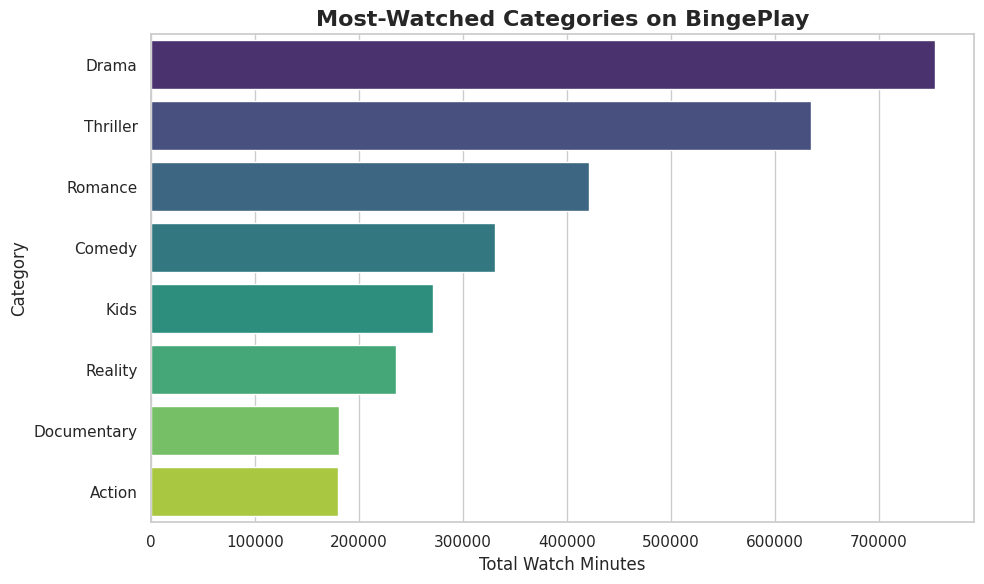

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=categories,
    x="total_watch_minutes",
    y="category",
    hue="category",
    palette="viridis",
    legend=False
)

plt.title("Most-Watched Categories on BingePlay",
          fontsize=16, fontweight="bold")
plt.xlabel("Total Watch Minutes")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

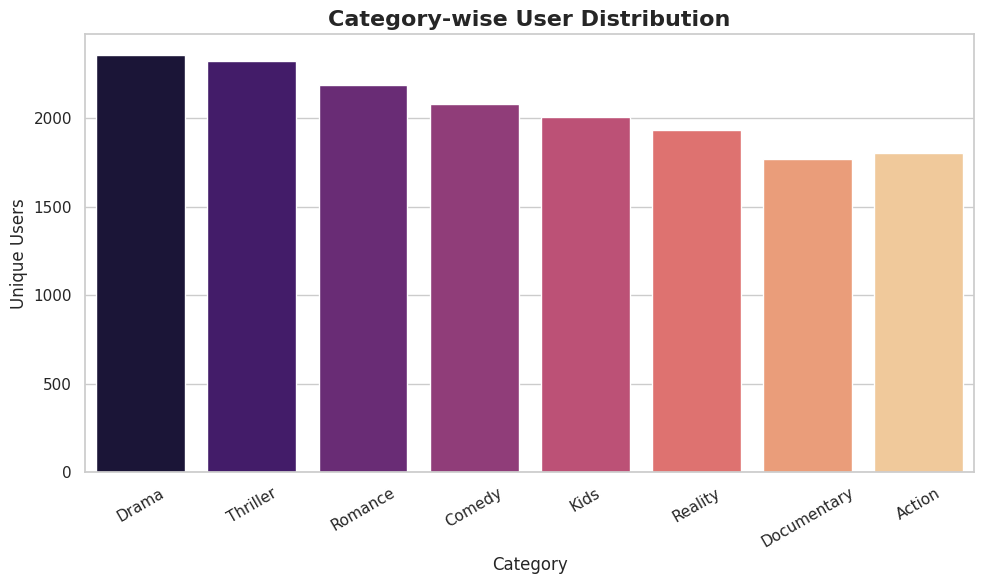

In [49]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=categories,
    x="category",
    y="unique_users",
    hue="category",
    palette="magma",
    legend=False
)

plt.title("Category-wise User Distribution",
          fontsize=16, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Unique Users")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

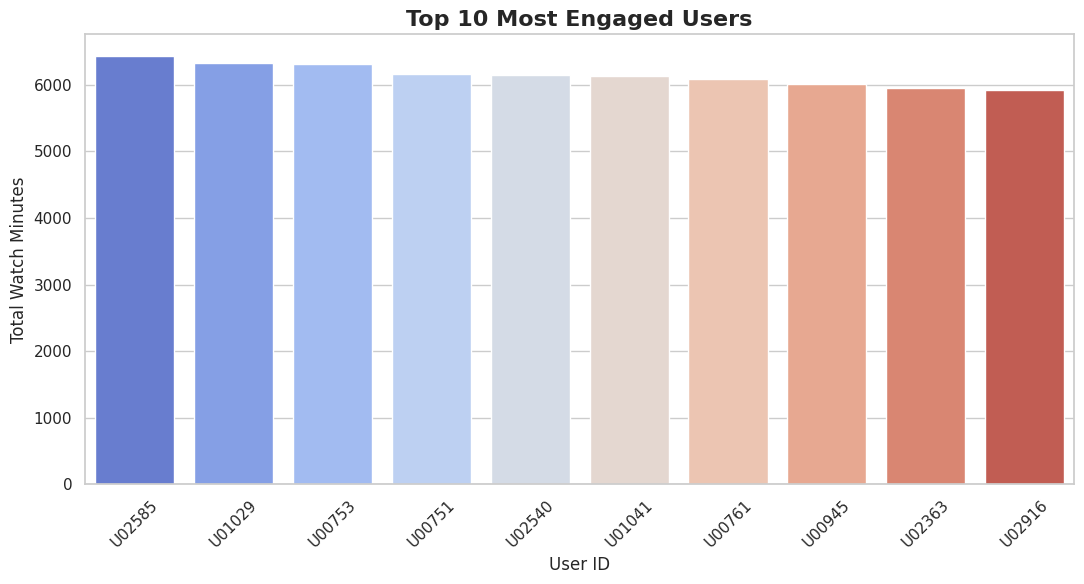

In [50]:
top_users = engagement.nlargest(
    10, "total_watch_minutes"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_users,
    x="user_id",
    y="total_watch_minutes",
    hue="user_id",
    palette="coolwarm",
    legend=False
)

plt.title("Top 10 Most Engaged Users",
          fontsize=16, fontweight="bold")
plt.xlabel("User ID")
plt.ylabel("Total Watch Minutes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

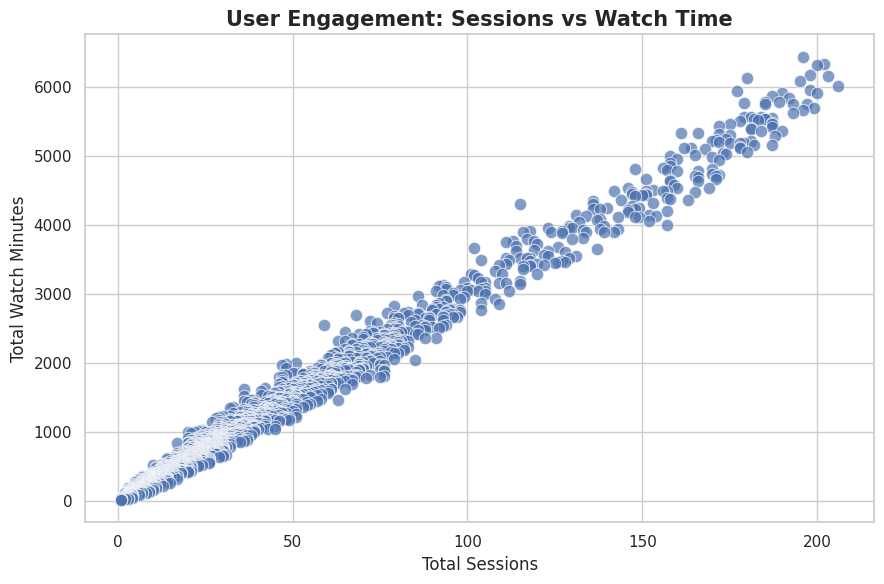

In [51]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=engagement,
    x="total_sessions",
    y="total_watch_minutes",
    s=80,
    alpha=0.7
)

plt.title("User Engagement: Sessions vs Watch Time",
          fontsize=15, fontweight="bold")
plt.xlabel("Total Sessions")
plt.ylabel("Total Watch Minutes")
plt.tight_layout()
plt.show()

BingePlay – Streaming Platform Data Analysis

1. Project Overview

BingePlay is a streaming platform data analysis project designed to understand user behaviour, viewing patterns, content popularity and subscription trends.

2. Objectives

* Analyse user subscription patterns.
* Identify popular content categories.
* Understand user engagement.
* Identify top-rated shows.
* Generate business insights using SQL and Python.
* Visualize important findings through charts.

3. Technologies Used

* Python
* SQL
* SQLite
* Google Colab
* Pandas
* Matplotlib
* Seaborn

4. Data Analysis Performed

* Database creation and data insertion.
* Data quality analysis.
* Missing value investigation.
* Dataset overview.
* Subscription distribution.
* Category distribution.
* Device analysis.
* Top-rated shows.
* Most-watched categories.
* User engagement analysis.
* Business insights.

5. Visualizations

* Most-watched categories bar chart.
* Category-wise user distribution.
* Top 10 engaged users.
* User engagement scatter plot.

6. Conclusion

The project provides insights into streaming platform performance, customer engagement and content preferences. These findings can help improve content recommendations, user retention and business strategies.
